# 8. Partición, desplazamiento y controles de fuga

El diseño de entrenamiento utiliza cinco folds de validación forward chaining dentro de 2000–2021 y reserva 2022–2025 para prueba. Los contrastes descriptivos entre 2000–2017 y 2018–2021 que se presentan a continuación caracterizan el desplazamiento temporal previo al benchmark. Sólo se muestran distribuciones del objetivo y covariables de entrenamiento/validación. Del tramo de prueba se usan calendario y controles de integridad/procedencia, sin explorar sus valores para decidir preprocesamiento.

KS se presenta como distancia descriptiva sin su p-valor IID; Wasserstein se normaliza con el IQR de entrenamiento. El intervalo de la diferencia de medias usa bootstrap de bloques móviles de 30 días, con 199 réplicas y semilla fija. Supone estabilidad aproximada dentro de cada periodo y se interpreta como diagnóstico.

El diseño de pronóstico considerado utiliza origen diario, contexto de una semana y salida directa de las siguientes 24 horas. Los conteos de ventanas sólo usan calendario: no leen valores de prueba. Los horizontes que atraviesan un corte se purgan. Deben cerrarse las decisiones restantes en un preregistro de benchmark antes de entrenar modelos.


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler
import collections
import datetime as dt
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from scipy import signal, stats

In [2]:
SEED = 11037
TARGET = 'precio_bolsa_cop_kwh'
ALLOWED_SOURCES = {'El Tiempo', 'El Espectador', 'Semana', 'Portafolio', 'La República', 'El Colombiano', 'Dinero', 'IDEAM', 'XM'}
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
RESULTS = ROOT / 'results'
WEATHER_PREFIXES = ('temperature_2m_c_', 'relative_humidity_2m_pct_', 'precipitation_preceding_hour_mm_')
CITIES = {'bogota', 'medellin', 'cali', 'barranquilla', 'cartagena', 'bucaramanga', 'pereira', 'cucuta'}
NUMERIC_E1 = {TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh', 'llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia'}
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def aware(value):
    parsed = dt.datetime.fromisoformat(value.replace('Z', '+00:00'))
    if parsed.tzinfo is None:
        raise ValueError('Timestamp must have an explicit timezone')
    return parsed

In [4]:
def eligible(record, origin):
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('availability_status') != 'verified_archived_version':
        return False
    if record.get('availability_proof') != 'wayback_payload_digest_and_capture':
        return False
    clean_flag = record.get('quarantined', False) in (False, 0, None, '', '0', 'false', 'False')
    if not re.fullmatch('[0-9a-f]{64}', record.get('version_sha256') or '') or not clean_flag:
        return False
    available = record.get('available_at_verified')
    captured = record.get('capture_at_verified')
    if not available or not captured:
        return False
    return aware(captured) <= aware(available) <= cutoff

In [5]:
def split_train_val_forwardChaining(sequence, numInputs, numOutputs, numJumps):
    """ Returns sets to train and cross-validate a model using forward chaining technique
    
    Parameters:
        sequence (array)  : Full training dataset
        numInputs (int)   : Number of inputs X and Xcv used at each training and validation
        numOutputs (int)  : Number of outputs y and ycv used at each training and validation
        numJumps (int)    : Number of sequence samples to be ignored between (X,y) sets

    Returns:
        X (2D array)    : Array of numInputs arrays used for training
        y (2D array)    : Array of numOutputs arrays used for training
        Xcv (2D array)  : Array of numInputs arrays used for cross-validation
        ycv (2D array)  : Array of numOutputs arrays used for cross-validation
        
    

Fuente: timeseries-cv 0.1.5; licencia original:
MIT License

Copyright (c) 2021 DidierRLopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

The MIT License (MIT)

Copyright (c) 2019 Didier Rodrigues Lopes

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
"""
    X, y, Xcv, ycv = (dict(), dict(), dict(), dict())
    j = 2
    while 1:
        start_ix = 0
        end_ix = 0
        startCv_ix = 0
        endCv_ix = 0
        X_it, y_it, Xcv_it, ycv_it = (list(), list(), list(), list())
        i = 0
        while i < j:
            start_ix = numJumps * i
            end_ix = start_ix + numInputs
            seq_x = sequence[start_ix:end_ix]
            X_it.append(seq_x)
            seq_y = sequence[end_ix:end_ix + numOutputs]
            y_it.append(seq_y)
            i += 1
        if end_ix + numInputs + numOutputs > len(sequence):
            break
        startCv_ix = end_ix
        endCv_ix = end_ix + numInputs
        seq_xcv = sequence[startCv_ix:endCv_ix]
        Xcv_it.append(seq_xcv)
        seq_ycv = sequence[endCv_ix:endCv_ix + numOutputs]
        ycv_it.append(seq_ycv)
        X[j - 2] = np.array(X_it)
        y[j - 2] = np.array(y_it)
        Xcv[j - 2] = np.array(Xcv_it)
        ycv[j - 2] = np.array(ycv_it)
        j += 1
    if len(X) == 0 or len(Xcv) == 0:
        print('The sequence provided does not has size enough to populate the return arrays')
    return (X, y, Xcv, ycv)

In [6]:
def validate_development_index(index, config):
    index = pd.DatetimeIndex(index)
    if index.tz is None:
        raise ValueError('El índice debe tener zona horaria.')
    index = index.tz_convert('America/Bogota')
    if len(index) < 2 or not index.is_monotonic_increasing or index.has_duplicates:
        raise ValueError('Índice temporal desordenado, duplicado o insuficiente.')
    if not np.all(np.diff(index.as_unit('ns').asi8) == pd.Timedelta(hours=1).value):
        raise ValueError('El calendario horario contiene huecos.')
    if index[0] < pd.Timestamp(config['development_start']) or index[-1] >= pd.Timestamp(config['development_end_exclusive']):
        raise PermissionError('La preparación sólo admite el periodo de desarrollo.')
    return index

In [7]:
def forward_chaining_folds(index, config, input_usable=None, target_usable=None):
    """Plan temporal por bloques; ventanas supervisadas completas y sin etiquetas compartidas."""
    index = validate_development_index(index, config)
    length = len(index)
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    origins = np.arange(lookback, length - horizon + 1, config['stride_hours'], dtype=np.int64)
    origins = origins[index[origins].hour == 0]
    if input_usable is not None:
        flags = np.asarray(input_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de entradas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins] - bad[origins - lookback] == 0]
    if target_usable is not None:
        flags = np.asarray(target_usable, dtype=bool)
        if flags.shape != (length,):
            raise ValueError('Máscara de etiquetas incompatible')
        bad = np.r_[0, np.cumsum(~flags)]
        origins = origins[bad[origins + horizon] - bad[origins] == 0]
    initial = origins[index[origins] < pd.Timestamp(config['validation_start'])]
    eligible = origins[index[origins] >= pd.Timestamp(config['validation_start'])]
    if len(initial) < 3 or len(eligible) < config['n_splits']:
        raise ValueError('Datos insuficientes para los folds.')
    validation_blocks = np.array_split(eligible, config['n_splits'])
    train_x, train_y, val_x, val_y = split_train_val_forwardChaining(np.arange(config['n_splits'] + 3), 1, 1, 1)
    if len(val_y) != config['n_splits']:
        raise AssertionError('Número inesperado de folds del backend')
    folds = []
    for key in sorted(val_y):
        block = int(val_y[key].ravel()[0])
        block_id = block - 3
        past_blocks = np.unique(np.r_[train_x[key].ravel(), train_y[key].ravel()])
        if past_blocks.max() >= block:
            raise AssertionError('El backend incluyó bloques futuros')
        start = int(validation_blocks[block_id][0])
        stop = int(validation_blocks[block_id + 1][0]) if block_id + 1 < len(validation_blocks) else length
        train = origins[origins + horizon <= start]
        validation = validation_blocks[block_id]
        validation = validation[validation + horizon <= stop]
        if not len(train) or not len(validation):
            raise ValueError('Fold vacío tras la purga de etiquetas')
        assert train[-1] + horizon <= validation[0]
        digest = hashlib.sha256(train.astype('<i8').tobytes() + validation.astype('<i8').tobytes()).hexdigest()
        folds.append(dict(fold=len(folds) + 1, train_origins=train, validation_origins=validation, validation_block=block, indices_sha256=digest))
    return folds

In [8]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [9]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [10]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [11]:
def assert_e1_features(names):
    for name in names:
        if name in NUMERIC_E1:
            continue
        if any((name == prefix + city for prefix in WEATHER_PREFIXES for city in CITIES)):
            continue
        if name in {'hour_sin', 'hour_cos', 'week_sin', 'week_cos', 'year_sin', 'year_cos'}:
            continue
        raise ValueError('E1 sólo admite las variables numéricas declaradas: ' + name)
    return True

In [12]:
def numeric_feature_frame(hourly, hydrology, config):
    index = validate_development_index(hourly.index, config)
    if not hydrology.index.is_monotonic_increasing or hydrology.index.has_duplicates:
        raise ValueError('Índice hidrológico no válido.')
    if hydrology.index.tz is None or (len(hydrology) and hydrology.index[-1] >= pd.Timestamp(config['development_end_exclusive'])):
        raise PermissionError('Hidrología fuera del periodo de desarrollo o sin zona horaria.')
    columns = [TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh']
    columns += sorted((c for c in hourly.columns if c.startswith(WEATHER_PREFIXES)))
    features = hourly[columns].shift(config['hourly_release_lag_hours']).copy()
    hydro_columns = ['llenado_valor_original', 'reserva_util_kwh', 'capacidad_util_kwh', 'aportes_kwh_dia']
    released = hydrology[hydro_columns].copy()
    released.index = released.index + pd.Timedelta(days=config['hydrology_release_lag_days'])
    features = features.join(released.reindex(index, method='ffill'))
    if config['include_calendar']:
        phases = {'hour': index.hour / 24, 'week': (index.day_of_week + index.hour / 24) / 7, 'year': (index.day_of_year - 1 + index.hour / 24) / np.where(index.is_leap_year, 366, 365)}
        for name, phase in phases.items():
            features[name + '_sin'] = np.sin(2 * np.pi * phase)
            features[name + '_cos'] = np.cos(2 * np.pi * phase)
    assert_e1_features(features.columns)
    return features

In [13]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [14]:
def build_training_pipeline(config=None, hourly=None, hydrology=None):
    config = pipeline_config(config)
    hourly = load_development_data() if hourly is None else hourly
    hydrology = load_development_data('hydrology') if hydrology is None else hydrology
    features = numeric_feature_frame(hourly, hydrology, config)
    target = hourly[TARGET].copy()
    usable = np.isfinite(features.to_numpy()).all(axis=1)
    folds = forward_chaining_folds(features.index, config, usable, np.isfinite(target.to_numpy()))
    return dict(config=config, features=features, target=target, folds=folds)

In [15]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [16]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [17]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [18]:
def pipeline_fold_summary(pipeline):
    rows = []
    index = pipeline['features'].index
    horizon = pipeline['config']['horizon_hours']
    for fold in pipeline['folds']:
        train = fold['train_origins']
        validation = fold['validation_origins']
        rows.append(dict(fold=fold['fold'], train_start=index[train[0]], train_end_exclusive=index[train[-1]] + pd.Timedelta(hours=horizon), validation_start=index[validation[0]], validation_end_exclusive=index[validation[-1]] + pd.Timedelta(hours=horizon), train_windows=len(train), validation_windows=len(validation), indices_sha256=fold['indices_sha256']))
    return pd.DataFrame(rows).set_index('fold')

In [19]:
def prepare_fold_arrays(pipeline, fold):
    features = pipeline['features']
    target = pipeline['target'].to_numpy()
    config = pipeline['config']
    lookback = config['lookback_hours']
    horizon = config['horizon_hours']
    train = fold['train_origins']
    validation = fold['validation_origins']
    train_positions = train[:, None] - lookback + np.arange(lookback)
    validation_positions = validation[:, None] - lookback + np.arange(lookback)
    train_rows = np.unique(train_positions)
    validation_rows = np.unique(validation_positions)
    scaler = StandardScaler().fit(features.iloc[train_rows])
    scaled_train = scaler.transform(features.iloc[train_rows]).astype(np.float32)
    scaled_validation = scaler.transform(features.iloc[validation_rows]).astype(np.float32)
    X_train = scaled_train[np.searchsorted(train_rows, train_positions)]
    X_validation = scaled_validation[np.searchsorted(validation_rows, validation_positions)]
    y_train = target[train[:, None] + np.arange(horizon)].astype(np.float32)
    y_validation = target[validation[:, None] + np.arange(horizon)].astype(np.float32)
    assert features.index[train_rows[-1]] < features.index[validation[0]]
    return dict(fold=fold['fold'], X_train=X_train, y_train=y_train, X_validation=X_validation, y_validation=y_validation, feature_scaler=scaler, feature_names=list(features.columns), train_origins=features.index[train], validation_origins=features.index[validation], scaler_fit_rows=len(train_rows), scaler_fit_start=features.index[train_rows[0]], scaler_fit_end=features.index[train_rows[-1]], target_units='COP/kWh')

In [20]:
def run_forward_chaining(pipeline, model_factory, fit_model, evaluate_model, seeds=(11037,)):
    """Extensión para modelos futuros: una instancia nueva por fold y semilla."""
    if not seeds:
        raise ValueError('Se requiere al menos una semilla.')
    rows = []
    for fold in pipeline['folds']:
        batch = prepare_fold_arrays(pipeline, fold)
        for seed in seeds:
            model = model_factory(seed=seed, n_features=len(batch['feature_names']), horizon=pipeline['config']['horizon_hours'])
            fitted = fit_model(model, batch, seed=seed)
            scores = evaluate_model(model if fitted is None else fitted, batch)
            rows.append(dict(fold=fold['fold'], seed=seed, **scores))
        del batch
    return pd.DataFrame(rows)

In [21]:
def split_for_labels(start, end_exclusive):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end_exclusive)
    if start.tzinfo is None or end.tzinfo is None:
        raise ValueError('Se requiere zona horaria.')
    for name, (a, b) in SPLITS.items():
        left = pd.Timestamp(f'{a}-01-01', tz='America/Bogota')
        right = pd.Timestamp(f'{b + 1}-01-01', tz='America/Bogota')
        if left <= start < end <= right:
            return name
    return 'purged'

In [22]:
def eligible_retrospective(record, origin):
    """Escenario autorizado: fecha declarada, SIN certificar versión histórica."""
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('quarantined', False) not in (False, 0, None, '', '0', 'false', 'False'):
        return False
    assumed = record.get('available_at_assumed')
    if not assumed or record.get('assumed_availability_basis') not in {'declared_timestamp_unverified_version', 'next_day_after_declared_date_unverified_version'}:
        return False
    return aware(assumed) <= cutoff

In [23]:
def select_before_origin(records, origin, scenario='verified'):
    aware(origin)
    if scenario not in {'verified', 'declared_dates'}:
        raise ValueError('Choose verified or declared_dates explicitly')
    rule = eligible if scenario == 'verified' else eligible_retrospective
    field = 'available_at_verified' if scenario == 'verified' else 'available_at_assumed'
    selected = [r for r in records if rule(r, origin)]
    return sorted(selected, key=lambda r: (aware(r[field]), r['id']))

In [24]:
def verify_guards():
    good = dict(id='a', source='IDEAM', availability_status='verified_archived_version', availability_proof='wayback_payload_digest_and_capture', version_sha256='a' * 64, capture_at_verified='2020-12-15T10:00:00-05:00', available_at_verified='2020-12-15T10:00:00-05:00', publication_date_claimed='2020-12-01', reference_period='2021-01')
    assert eligible(good, '2020-12-15T10:00:00-05:00')
    assert not eligible(good, '2020-12-15T09:59:59-05:00')
    assert eligible(good, '2020-12-15T15:00:00+00:00')
    assert not eligible(dict(good, source='El Heraldo'), '2025-01-01T00:00:00-05:00')
    assert not eligible(dict(good, availability_status='unverified'), '2025-01-01T00:00:00-05:00')
    assert not eligible(dict(good, available_at_verified=None, available_at_assumed='2020-12-02T00:00:00-05:00'), '2021-01-01T00:00:00-05:00')
    assert not eligible(dict(good, capture_at_verified='2026-11-03T00:00:00-05:00', available_at_verified='2026-11-03T00:00:00-05:00'), '2021-01-01T00:00:00-05:00')
    assert not eligible(dict(good, quarantined=True), '2025-01-01T00:00:00-05:00')
    assert eligible(dict(good, quarantined='0'), '2020-12-15T10:00:00-05:00')
    assert not eligible(dict(good, quarantined='1'), '2025-01-01T00:00:00-05:00')
    assert not eligible(dict(good, version_sha256='not-a-hash'), '2025-01-01T00:00:00-05:00')
    declared = dict(good, availability_status='historical_version_unverified', available_at_verified=None, capture_at_verified=None, version_sha256=None, available_at_assumed='2020-12-02T00:00:00-05:00', assumed_availability_basis='next_day_after_declared_date_unverified_version')
    assert eligible_retrospective(declared, '2020-12-02T00:00:00-05:00')
    assert not eligible_retrospective(declared, '2020-12-01T23:59:59-05:00')
    assert not eligible(declared, '2025-01-01T00:00:00-05:00')
    assert not eligible_retrospective(dict(declared, available_at_assumed=None), '2025-01-01T00:00:00-05:00')
    assert [r['id'] for r in select_before_origin([declared], '2020-12-02T00:00:00-05:00', 'declared_dates')] == ['a']
    try:
        select_before_origin([good], '2020-12-15T10:00:00')
    except ValueError:
        pass
    else:
        raise AssertionError('Naive origin accepted')
    assert [r['id'] for r in select_before_origin([dict(good, id='b'), good], '2020-12-15T10:00:00-05:00')] == ['a', 'b']
    print('OK: versiones, captura, fechas futuras, supuestos, fuentes excluidas y zona horaria.')

In [25]:
train = load_numeric()
valid = load_numeric('validation')
rows = []
for split, frame in [('train', train), ('validation', valid)]:
    for c in [TARGET, 'demanda_real_kwh', 'temperature_2m_c_bogota', 'relative_humidity_2m_pct_barranquilla']:
        x = frame[c]
        rows.append(dict(particion=split, variable=c, n=len(x), media=x.mean(), mediana=x.median(), sd=x.std(), p01=x.quantile(0.01), p99=x.quantile(0.99)))
table(pd.DataFrame(rows).set_index(['variable', 'particion']), 'distribuciones_train_validacion')

,,n,media,mediana,sd,p01,p99
variable,particion,,,,,,
precio_bolsa_cop_kwh,train,157800,124.56,84.405,140.41,28.794,822.44
demanda_real_kwh,train,157800,6.1907e+06,6.1196e+06,1.3957e+06,3.396e+06,9.064e+06
temperature_2m_c_bogota,train,157800,14.903,14.1,3.4963,9.1,22.7
relative_humidity_2m_pct_barranquilla,train,157800,82.437,85,12.399,49,99
precio_bolsa_cop_kwh,validation,35064,186.48,155.21,107.04,67.955,502.3
demanda_real_kwh,validation,35064,8.0435e+06,8.0947e+06,1.1141e+06,5.908e+06,1.0057e+07
temperature_2m_c_bogota,validation,35064,14.797,14.1,3.2458,8.9,21.7
relative_humidity_2m_pct_barranquilla,validation,35064,80.729,83,12.893,47,99


In [26]:
shifts = []
for c in [TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh', 'temperature_2m_c_bogota', 'relative_humidity_2m_pct_barranquilla']:
    a = train[c].resample('D').mean().to_numpy()
    b = valid[c].resample('D').mean().to_numpy()
    scale = np.quantile(a, 0.75) - np.quantile(a, 0.25)
    shifts.append(dict(variable=c, ks_D_descriptivo=stats.ks_2samp(a, b).statistic, wasserstein_div_IQR_train=stats.wasserstein_distance(a, b) / scale, diferencia_media_div_sd_train=(b.mean() - a.mean()) / a.std()))
table(pd.DataFrame(shifts).set_index('variable'), 'desplazamiento_train_validacion')

,ks_D_descriptivo,wasserstein_div_IQR_train,diferencia_media_div_sd_train
variable,,,
precio_bolsa_cop_kwh,0.44691,0.96208,0.44921
demanda_real_kwh,0.70806,1.1718,1.835
demanda_comercial_kwh,0.70631,1.1649,1.8283
temperature_2m_c_bogota,0.039557,0.09566,-0.12368
relative_humidity_2m_pct_barranquilla,0.10834,0.1583,-0.25779


In [27]:
a = train[TARGET].resample('D').mean().to_numpy()
b = valid[TARGET].resample('D').mean().to_numpy()
rng = np.random.default_rng(SEED)
block = 30

def resample(x):
    starts = rng.integers(0, len(x) - block + 1, size=int(np.ceil(len(x) / block)))
    return np.concatenate([x[i:i + block] for i in starts])[:len(x)]
diffs = np.array([resample(b).mean() - resample(a).mean() for _ in range(199)])
table(pd.DataFrame({'diferencia_media_COP_kWh': [b.mean() - a.mean()], 'IC95_bloques_inferior': [np.quantile(diffs, 0.025)], 'IC95_bloques_superior': [np.quantile(diffs, 0.975)], 'dias_bloque': [block], 'replicas': [199]}), 'bootstrap_shift_train_validacion')

,diferencia_media_COP_kWh,IC95_bloques_inferior,IC95_bloques_superior,dias_bloque,replicas
0,61.918,31.047,93.127,30,199


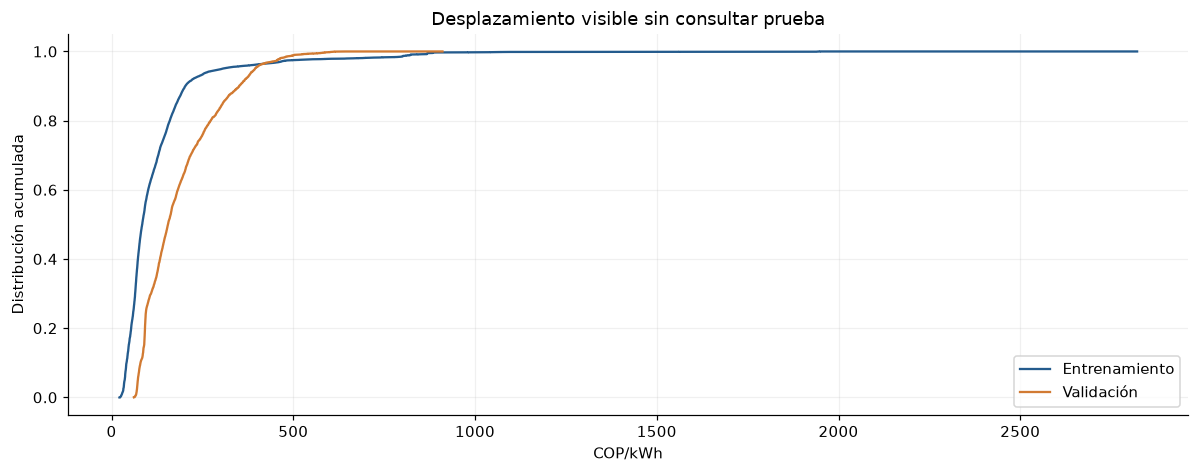

In [28]:
fig, ax = plt.subplots()
for name, frame in [('Entrenamiento', train), ('Validación', valid)]:
    x = np.sort(frame[TARGET].to_numpy())
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=name)
ax.set(xlabel='COP/kWh', ylabel='Distribución acumulada', title='Desplazamiento visible sin consultar prueba')
ax.legend()
figure(fig, 'shift_train_validacion')

In [29]:
calendar = pd.date_range('2000-01-01', '2026-01-01', freq='h', inclusive='left', tz='America/Bogota')
origins = calendar[168:-23]
origins = origins[origins.hour == 0]
labels = collections.Counter((split_for_labels(t, t + pd.Timedelta(hours=24)) for t in origins))
table(pd.Series(labels, name='origenes_candidatos_calendario').to_frame(), 'ventanas_calendario_sin_leer_prueba')

,origenes_candidatos_calendario
train,6568
validation,1461
test,1461


In [30]:
tests = []
verify_guards()
try:
    load_numeric('test')
except PermissionError:
    tests.append(('carga de prueba bloqueada por defecto', True))
else:
    raise AssertionError('Test access allowed')
assert split_for_labels('2017-12-31T12:00:00-05:00', '2018-01-01T12:00:00-05:00') == 'purged'
tests.append(('horizonte que cruza corte eliminado', True))
table(pd.DataFrame(tests, columns=['control', 'pasa']).set_index('control'), 'controles_fuga')

OK: versiones, captura, fechas futuras, supuestos, fuentes excluidas y zona horaria.


,pasa
control,
carga de prueba bloqueada por defecto,True
horizonte que cruza corte eliminado,True


In [31]:
display(Markdown('El estadístico KS se presenta sin su p-valor IID: los días son dependientes. Wasserstein es un tamaño de desplazamiento, no prueba causal. El bootstrap de bloques conserva dependencia local y presupone estabilidad aproximada dentro de cada periodo; no corrige cambios estructurales por sí solo. Las ventanas se cuentan desde el calendario, sin leer los valores de prueba.'))

El estadístico KS se presenta sin su p-valor IID: los días son dependientes. Wasserstein es un tamaño de desplazamiento, no prueba causal. El bootstrap de bloques conserva dependencia local y presupone estabilidad aproximada dentro de cada periodo; no corrige cambios estructurales por sí solo. Las ventanas se cuentan desde el calendario, sin leer los valores de prueba.

In [32]:
decision('Ajustar toda transformación sólo con train. Si se recalibra con origen móvil, usar únicamente datos anteriores al origen y una política cerrada antes de prueba.', 'Comparar capacidad de adaptación de modelos con el mismo presupuesto; no seleccionar una red con estas estadísticas de validación.', 'Prueba congelada; sólo integridad/calendario/cobertura. Contexto pasado puede atravesar el corte, etiquetas futuras no. Origen es inicio del intervalo a pronosticar.', 'El uso exploratorio de validación y la incertidumbre sobre disponibilidad y revisiones deben incorporarse a la interpretación de la evaluación predictiva.')

### Implicaciones del análisis

- **Preprocesamiento:** Ajustar toda transformación sólo con train. Si se recalibra con origen móvil, usar únicamente datos anteriores al origen y una política cerrada antes de prueba.
- **Arquitectura:** Comparar capacidad de adaptación de modelos con el mismo presupuesto; no seleccionar una red con estas estadísticas de validación.
- **Validación:** Prueba congelada; sólo integridad/calendario/cobertura. Contexto pasado puede atravesar el corte, etiquetas futuras no. Origen es inicio del intervalo a pronosticar.
- **Riesgos:** El uso exploratorio de validación y la incertidumbre sobre disponibilidad y revisiones deben incorporarse a la interpretación de la evaluación predictiva.

## 8.1 Pipeline de validación forward chaining

La función `split_train_val_forwardChaining` de timeseries-cv 0.1.5 organiza una secuencia de bloques temporales. Los bloques se traducen a orígenes diarios de pronóstico: el entrenamiento se amplía con cada fold y la validación corresponde siempre a un periodo posterior. Se conservan únicamente ventanas cuyas etiquetas están completas dentro del bloque asignado.

El contexto comprende 168 horas, el horizonte 24 horas y el paso entre orígenes 24 horas. La preparación incorpora un rezago supuesto de publicación de 24 horas para variables horarias y dos días para hidrología. Cada escalador se ajusta exclusivamente con las filas usadas en las entradas de entrenamiento de su fold. Las etiquetas se conservan en COP/kWh.

El pipeline admite funciones de construcción, ajuste y evaluación de modelos, con una instancia nueva por fold y semilla. Los parámetros y los artefactos de preparación se registran en `configs/training_pipeline.json` y `results/pipeline/`. [Fuente del método](https://pypi.org/project/timeseries-cv/).

In [33]:
training_pipeline = build_training_pipeline(load_pipeline_config())
folds = pipeline_fold_summary(training_pipeline)
table(folds, 'forward_chaining_folds')

,train_start,train_end_exclusive,validation_start,validation_end_exclusive,train_windows,validation_windows,indices_sha256
fold,,,,,,,
1,2000-01-10 00:00:00-05:00,2018-01-01 00:00:00-05:00,2018-01-01 00:00:00-05:00,2018-10-21 00:00:00-05:00,6566,293,6fa9dd803520960d6490f346faa559001ef4ad70e55d92...
2,2000-01-10 00:00:00-05:00,2018-10-21 00:00:00-05:00,2018-10-21 00:00:00-05:00,2019-08-09 00:00:00-05:00,6859,292,014e7386223c308087ce1e13a0c24a12c241c13e357dce...
3,2000-01-10 00:00:00-05:00,2019-08-09 00:00:00-05:00,2019-08-09 00:00:00-05:00,2020-05-27 00:00:00-05:00,7151,292,2c196fa925cb7ad23ad42a53d361166798b640a1ebfaea...
4,2000-01-10 00:00:00-05:00,2020-05-27 00:00:00-05:00,2020-05-27 00:00:00-05:00,2021-03-15 00:00:00-05:00,7443,292,14c6e0b6eea5f896b0f3e824f9ce903a261aa518a36ca5...
5,2000-01-10 00:00:00-05:00,2021-03-15 00:00:00-05:00,2021-03-15 00:00:00-05:00,2022-01-01 00:00:00-05:00,7735,292,7f4d1acbc3747a56c26949acb1a6be78aec540a94fc922...


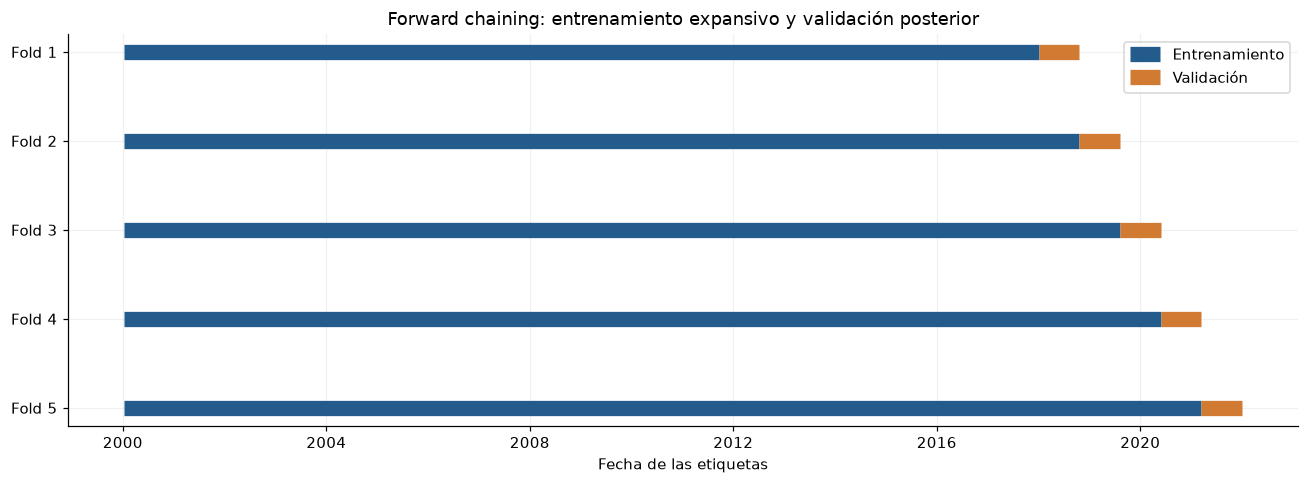

In [34]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, (_, row) in enumerate(folds.iterrows()):
    ax.plot([row['train_start'], row['train_end_exclusive']], [i, i], lw=10, color='#245b8d', label='Entrenamiento' if i == 0 else None, solid_capstyle='butt')
    ax.plot([row['validation_start'], row['validation_end_exclusive']], [i, i], lw=10, color='#d17a32', label='Validación' if i == 0 else None, solid_capstyle='butt')
ax.set_yticks(range(len(folds)), ['Fold ' + str(f) for f in folds.index])
ax.invert_yaxis()
ax.set(xlabel='Fecha de las etiquetas', title='Forward chaining: entrenamiento expansivo y validación posterior')
ax.legend()
figure(fig, 'forward_chaining_folds')

In [35]:
batch = prepare_fold_arrays(training_pipeline, training_pipeline['folds'][0])
preparation = pd.DataFrame([dict(fold=batch['fold'], entradas_entrenamiento=str(batch['X_train'].shape), etiquetas_entrenamiento=str(batch['y_train'].shape), entradas_validacion=str(batch['X_validation'].shape), etiquetas_validacion=str(batch['y_validation'].shape), filas_ajuste_escalador=batch['scaler_fit_rows'], inicio_ajuste=batch['scaler_fit_start'], fin_ajuste=batch['scaler_fit_end'])])
table(preparation.set_index('fold'), 'forward_chaining_preprocessing_example')

,entradas_entrenamiento,etiquetas_entrenamiento,entradas_validacion,etiquetas_validacion,filas_ajuste_escalador,inicio_ajuste,fin_ajuste
fold,,,,,,,
1,"(6566, 168, 37)","(6566, 24)","(293, 168, 37)","(293, 24)",157728,2000-01-03 00:00:00-05:00,2017-12-30 23:00:00-05:00


In [36]:
del batch

def train_reference_models(model_factory, fit_model, evaluate_model, seeds):
    return run_forward_chaining(training_pipeline, model_factory, fit_model, evaluate_model, seeds)

In [37]:
decision('Alinear las covariables con sus fechas de disponibilidad supuestas y ajustar el escalado con las entradas de entrenamiento de cada fold.', 'Mantener una interfaz común de ventanas multivariadas y salida directa de 24 horas para los modelos de referencia.', 'Aplicar cinco folds forward chaining sobre desarrollo 2000–2021; reservar 2022–2025 para la evaluación final.', 'Los rezagos de publicación constituyen supuestos retrospectivos; su sensibilidad debe evaluarse antes de interpretar un desempeño operativo.')

### Implicaciones del análisis

- **Preprocesamiento:** Alinear las covariables con sus fechas de disponibilidad supuestas y ajustar el escalado con las entradas de entrenamiento de cada fold.
- **Arquitectura:** Mantener una interfaz común de ventanas multivariadas y salida directa de 24 horas para los modelos de referencia.
- **Validación:** Aplicar cinco folds forward chaining sobre desarrollo 2000–2021; reservar 2022–2025 para la evaluación final.
- **Riesgos:** Los rezagos de publicación constituyen supuestos retrospectivos; su sensibilidad debe evaluarse antes de interpretar un desempeño operativo.